In [4]:
import os
import sys
import warnings
warnings.filterwarnings('ignore')

# Add parent directory to path to import from helpers
current_dir = os.getcwd()
parent_dir = os.path.abspath(os.path.join(current_dir, '..'))

if parent_dir not in sys.path:
    sys.path.insert(0, parent_dir)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# NLP processing
from helpers.nlp import TextFeatureExtractor, combine_text_columns

# Scikit-learn
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report, confusion_matrix, roc_curve, auc
from sklearn.preprocessing import StandardScaler

# Neural Network
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks, regularizers
from tensorflow.keras.optimizers import Adam

# Set random seeds for reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

print("✅ All libraries imported successfully!")
print(f"TensorFlow version: {tf.__version__}")
print(f"GPU available: {len(tf.config.list_physical_devices('GPU')) > 0}")


✅ All libraries imported successfully!
TensorFlow version: 2.20.0
GPU available: False


In [5]:
# Load data
print("="*70)
print("LOADING DATA")
print("="*70)

train = pd.read_csv('../data/train.csv')
test = pd.read_csv('../data/test.csv')

# Separate features and target
y_train = train['target'].copy()

print(f"\n📊 Dataset Summary:")
print(f"  Training samples: {len(train):,}")
print(f"  Test samples: {len(test):,}")
print(f"  Features: {train.shape[1] - 1}")

print(f"\n🎯 Target Distribution:")
target_counts = y_train.value_counts().sort_index()
for label, count in target_counts.items():
    percentage = (count / len(y_train)) * 100
    emoji = "🤖" if label == 1 else "👤"
    print(f"  {emoji} Class {label}: {count:,} samples ({percentage:.1f}%)")

print("\n✅ Data loaded successfully!")


LOADING DATA

📊 Dataset Summary:
  Training samples: 26,206
  Test samples: 11,232
  Features: 18

🎯 Target Distribution:
  👤 Class 0: 17,423 samples (66.5%)
  🤖 Class 1: 8,783 samples (33.5%)

✅ Data loaded successfully!


In [6]:
# Extract and combine text features for NLP processing
print("="*70)
print("TEXT FEATURE EXTRACTION")
print("="*70)

# Define text columns to process
TEXT_COLUMNS = ['location', 'description', 'screen_name']

print(f"\n📝 Processing text columns: {TEXT_COLUMNS}")

# Combine text columns for train and test
print("\n1. Combining text columns...")
train_text = combine_text_columns(train, columns=TEXT_COLUMNS)
test_text = combine_text_columns(test, columns=TEXT_COLUMNS)

print(f"  Train text shape: {train_text.shape}")
print(f"  Test text shape: {test_text.shape}")

# Show examples
print(f"\n  Sample combined text:")
for i in range(3):
    text_sample = train_text.iloc[i]
    if len(text_sample) > 100:
        text_sample = text_sample[:100] + "..."
    print(f"    [{i}]: {text_sample}")

# Initialize text feature extractor
print(f"\n2. Initializing TextFeatureExtractor...")
print(f"  Configuration:")
print(f"    - Word TF-IDF features: 30,000")
print(f"    - Char TF-IDF features: 30,000")
print(f"    - SVD components: 300")

text_extractor = TextFeatureExtractor(
    max_features_word=30000,
    max_features_char=30000,
    n_components=300,
    word_ngram_range=(1, 2),
    char_ngram_range=(3, 5),
    min_df=2,
    max_df=0.95,
    use_idf=True,
    sublinear_tf=True,
    random_state=RANDOM_STATE,
    verbose=True,
    use_gpu=False  # Set to True if cuML is available
)

# Fit and transform training data
print(f"\n3. Fitting on training data...")
X_text_train = text_extractor.fit_transform(train_text)

# Transform test data
print(f"\n4. Transforming test data...")
X_text_test = text_extractor.transform(test_text)

print(f"\n✅ Text features extracted successfully!")
print(f"  Training text features shape: {X_text_train.shape}")
print(f"  Test text features shape: {X_text_test.shape}")

# Convert to DataFrame for easier handling
text_feature_names = text_extractor.get_feature_names()
X_text_train_df = pd.DataFrame(X_text_train, columns=text_feature_names, index=train.index)
X_text_test_df = pd.DataFrame(X_text_test, columns=text_feature_names, index=test.index)

print(f"\n📊 Text Feature Statistics:")
print(f"  Mean: {X_text_train.mean():.4f}")
print(f"  Std:  {X_text_train.std():.4f}")
print(f"  Min:  {X_text_train.min():.4f}")
print(f"  Max:  {X_text_train.max():.4f}")


TEXT FEATURE EXTRACTION

📝 Processing text columns: ['location', 'description', 'screen_name']

1. Combining text columns...
  Train text shape: (26206,)
  Test text shape: (11232,)

  Sample combined text:
    [0]: unknown Cosplayer/Fitness lover. Come to me https://t.co/8HhtbVhTdW reml5477
    [1]: she/her  pobody’s nerfect kinlibra
    [2]: La diaspora gracias por participar 🏅 _delaualau

2. Initializing TextFeatureExtractor...
  Configuration:
    - Word TF-IDF features: 30,000
    - Char TF-IDF features: 30,000
    - SVD components: 300
ℹ️  Using CPU-based scikit-learn (cuML not available)

3. Fitting on training data...
FITTING TEXT FEATURE EXTRACTOR
Number of texts: 26206

1. Fitting word-level TF-IDF (ngrams=(1, 2))...
   Word features shape: (26206, 30000)
   Vocabulary size: 30000

2. Fitting character-level TF-IDF (ngrams=(3, 5))...
   Word features shape: (26206, 30000)
   Vocabulary size: 30000

2. Fitting character-level TF-IDF (ngrams=(3, 5))...
   Char features shape: (

# Neural Network Configuration

In [7]:
# =============================================================================
# NEURAL NETWORK CONFIGURATION
# =============================================================================

# Model architecture
N_HIDDEN_LAYERS = 3
HIDDEN_UNITS = [512, 256, 128]
DROPOUT_RATE = 0.3
L2_REG = 0.001

# Training configuration
BATCH_SIZE = 128
EPOCHS = 100
LEARNING_RATE = 0.001
EARLY_STOPPING_PATIENCE = 15

# Cross-validation
N_SPLITS = 5

print("="*70)
print("NEURAL NETWORK CONFIGURATION")
print("="*70)
print(f"\n🏗️ Architecture:")
print(f"  Input features: {X_text_train_df.shape[1]}")
print(f"  Hidden layers: {N_HIDDEN_LAYERS}")
print(f"  Hidden units: {HIDDEN_UNITS}")
print(f"  Dropout rate: {DROPOUT_RATE}")
print(f"  L2 regularization: {L2_REG}")

print(f"\n⚙️ Training:")
print(f"  Batch size: {BATCH_SIZE}")
print(f"  Max epochs: {EPOCHS}")
print(f"  Learning rate: {LEARNING_RATE}")
print(f"  Early stopping patience: {EARLY_STOPPING_PATIENCE}")

print(f"\n🔄 Cross-validation:")
print(f"  Folds: {N_SPLITS}")
print("="*70)


NEURAL NETWORK CONFIGURATION

🏗️ Architecture:
  Input features: 300
  Hidden layers: 3
  Hidden units: [512, 256, 128]
  Dropout rate: 0.3
  L2 regularization: 0.001

⚙️ Training:
  Batch size: 128
  Max epochs: 100
  Learning rate: 0.001
  Early stopping patience: 15

🔄 Cross-validation:
  Folds: 5


In [8]:
# Build Neural Network Model
def build_mlp_model(input_dim, hidden_units=HIDDEN_UNITS, dropout_rate=DROPOUT_RATE, l2_reg=L2_REG, learning_rate=LEARNING_RATE):
    """
    Build a Multi-Layer Perceptron (MLP) model for binary classification.
    
    Parameters:
    -----------
    input_dim : int
        Number of input features
    hidden_units : list
        List of hidden layer sizes
    dropout_rate : float
        Dropout rate for regularization
    l2_reg : float
        L2 regularization strength
    learning_rate : float
        Learning rate for optimizer
    
    Returns:
    --------
    model : keras.Model
        Compiled Keras model
    """
    model = keras.Sequential(name='MLP_TextClassifier')
    
    # Input layer
    model.add(layers.Input(shape=(input_dim,), name='text_input'))
    
    # Hidden layers with batch normalization and dropout
    for i, units in enumerate(hidden_units):
        model.add(layers.Dense(
            units, 
            activation='relu',
            kernel_regularizer=regularizers.l2(l2_reg),
            name=f'hidden_{i+1}'
        ))
        model.add(layers.BatchNormalization(name=f'bn_{i+1}'))
        model.add(layers.Dropout(dropout_rate, name=f'dropout_{i+1}'))
    
    # Output layer
    model.add(layers.Dense(1, activation='sigmoid', name='output'))
    
    # Compile model
    model.compile(
        optimizer=Adam(learning_rate=learning_rate),
        loss='binary_crossentropy',
        metrics=[
            'accuracy',
            keras.metrics.AUC(name='auc'),
            keras.metrics.Precision(name='precision'),
            keras.metrics.Recall(name='recall')
        ]
    )
    
    return model

# Build and display model architecture
print("="*70)
print("BUILDING NEURAL NETWORK MODEL")
print("="*70)

model = build_mlp_model(input_dim=X_text_train_df.shape[1])

print("\n📋 Model Summary:")
model.summary()

print(f"\n✅ Model built successfully!")
print(f"  Total parameters: {model.count_params():,}")
print(f"  Trainable parameters: {sum([tf.size(w).numpy() for w in model.trainable_weights]):,}")


BUILDING NEURAL NETWORK MODEL

📋 Model Summary:


Model: "MLP_TextClassifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_1 (Dense)                │ (None, 512)            │       154,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_1 (BatchNormalization)       │ (None, 512)            │         2,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_2 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_2 (BatchNormalization)       │ (None, 256)            │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_3 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_3 (BatchNormalization)       │ (None, 128)            │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 322,049 (1.23 MB)

 Trainable params: 320,257 (1.22 MB)

 Non-trainable params: 1,792 (7.00 KB)


✅ Model built successfully!
  Total parameters: 322,049
  Trainable parameters: 320,257


In [9]:
# Train MLP with 5-fold Cross Validation
print("\n" + "="*70)
print("TRAINING MLP WITH 5-FOLD CROSS-VALIDATION")
print("="*70)

# Setup cross-validation
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)

# Storage for results
oof_predictions = np.zeros(len(y_train))
test_predictions_folds = []
cv_scores = []
fold_histories = []

# Scale features (important for neural networks)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_text_train_df)
X_test_scaled = scaler.transform(X_text_test_df)

print(f"\n✅ Features scaled using StandardScaler")
print(f"  Scaled feature mean: {X_train_scaled.mean():.6f}")
print(f"  Scaled feature std: {X_train_scaled.std():.6f}")

# Cross-validation loop
for fold, (train_idx, val_idx) in enumerate(skf.split(X_train_scaled, y_train), 1):
    print(f"\n{'='*20} FOLD {fold}/{N_SPLITS} {'='*20}")
    
    # Split data
    X_train_fold = X_train_scaled[train_idx]
    X_val_fold = X_train_scaled[val_idx]
    y_train_fold = y_train.iloc[train_idx].values
    y_val_fold = y_train.iloc[val_idx].values
    
    print(f"  Train: {X_train_fold.shape}, Val: {X_val_fold.shape}")
    
    # Build model for this fold
    model_fold = build_mlp_model(
        input_dim=X_train_scaled.shape[1],
        hidden_units=HIDDEN_UNITS,
        dropout_rate=DROPOUT_RATE,
        l2_reg=L2_REG,
        learning_rate=LEARNING_RATE
    )
    
    # Callbacks
    early_stop = callbacks.EarlyStopping(
        monitor='val_auc',
        patience=EARLY_STOPPING_PATIENCE,
        restore_best_weights=True,
        mode='max',
        verbose=0
    )
    
    reduce_lr = callbacks.ReduceLROnPlateau(
        monitor='val_auc',
        factor=0.5,
        patience=5,
        min_lr=1e-7,
        mode='max',
        verbose=0
    )
    
    # Train model
    print(f"  Training model...")
    history = model_fold.fit(
        X_train_fold, y_train_fold,
        validation_data=(X_val_fold, y_val_fold),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=[early_stop, reduce_lr],
        verbose=0
    )
    
    fold_histories.append(history)
    
    # Predict on validation fold
    val_pred = model_fold.predict(X_val_fold, verbose=0).flatten()
    oof_predictions[val_idx] = val_pred
    
    # Predict on test set
    test_pred = model_fold.predict(X_test_scaled, verbose=0).flatten()
    test_predictions_folds.append(test_pred)
    
    # Calculate fold metrics
    fold_auc = roc_auc_score(y_val_fold, val_pred)
    fold_acc = accuracy_score(y_val_fold, (val_pred > 0.5).astype(int))
    cv_scores.append(fold_auc)
    
    # Get best epoch
    best_epoch = np.argmax(history.history['val_auc']) + 1
    best_val_auc = max(history.history['val_auc'])
    
    print(f"  Best epoch: {best_epoch}/{len(history.history['loss'])}")
    print(f"  Validation AUC: {fold_auc:.4f}")
    print(f"  Validation Accuracy: {fold_acc:.4f}")

# Average test predictions across folds
test_predictions = np.mean(test_predictions_folds, axis=0)

# Overall CV performance
overall_auc = roc_auc_score(y_train, oof_predictions)
overall_acc = accuracy_score(y_train, (oof_predictions > 0.5).astype(int))

print(f"\n{'='*70}")
print("CROSS-VALIDATION RESULTS")
print(f"{'='*70}")
print(f"\n📊 Overall Performance:")
print(f"  Mean CV AUC: {np.mean(cv_scores):.4f} (+/- {np.std(cv_scores):.4f})")
print(f"  OOF AUC: {overall_auc:.4f}")
print(f"  OOF Accuracy: {overall_acc:.4f}")
print(f"\n📈 Individual Fold AUCs:")
for i, score in enumerate(cv_scores, 1):
    print(f"  Fold {i}: {score:.4f}")

print(f"\n{'='*70}")



TRAINING MLP WITH 5-FOLD CROSS-VALIDATION

✅ Features scaled using StandardScaler
  Scaled feature mean: 0.000000
  Scaled feature std: 1.000000

==================== FOLD 1/5 ====================
  Train: (20964, 300), Val: (5242, 300)
  Train: (20964, 300), Val: (5242, 300)
  Training model...
  Training model...
  Best epoch: 6/21
  Validation AUC: 0.8058
  Validation Accuracy: 0.7659

==================== FOLD 2/5 ====================
  Train: (20965, 300), Val: (5241, 300)
  Training model...
  Best epoch: 6/21
  Validation AUC: 0.8058
  Validation Accuracy: 0.7659

==================== FOLD 2/5 ====================
  Train: (20965, 300), Val: (5241, 300)
  Training model...
  Best epoch: 3/18
  Validation AUC: 0.8082
  Validation Accuracy: 0.7645

==================== FOLD 3/5 ====================
  Train: (20965, 300), Val: (5241, 300)
  Training model...
  Best epoch: 3/18
  Validation AUC: 0.8082
  Validation Accuracy: 0.7645

==================== FOLD 3/5 ===================

In [10]:
# Generate submission file
print("="*70)
print("GENERATING SUBMISSION")
print("="*70)

# Create submission dataframe
submission = pd.DataFrame({
    'index': test['index'],
    'target': test_predictions
})

# Save submission
os.makedirs('../submissions', exist_ok=True)
submission_path = '../submissions/NN_MLP.csv'
submission.to_csv(submission_path, index=False)

print(f"\n✅ Submission saved to: {submission_path}")

print(f"\n📊 Prediction Statistics:")
print(f"  Min:  {test_predictions.min():.4f}")
print(f"  Max:  {test_predictions.max():.4f}")
print(f"  Mean: {test_predictions.mean():.4f}")
print(f"  Std:  {test_predictions.std():.4f}")

print(f"\n📋 First 10 predictions:")
print(submission.head(10).to_string(index=False))

# Save trained artifacts
os.makedirs('trained', exist_ok=True)

# Save text extractor
text_extractor_path = 'trained/text_extractor.joblib'
joblib.dump(text_extractor, text_extractor_path)
print(f"\n💾 Text extractor saved to: {text_extractor_path}")

# Save scaler
scaler_path = 'trained/scaler_mlp.joblib'
joblib.dump(scaler, scaler_path)
print(f"💾 Scaler saved to: {scaler_path}")

# Save OOF predictions
oof_path = 'oof_predictions/oof_mlp.pkl'
os.makedirs('oof_predictions', exist_ok=True)
joblib.dump(oof_predictions, oof_path)
print(f"💾 OOF predictions saved to: {oof_path}")

print(f"\n{'='*70}")
print("SUBMISSION COMPLETE!")
print(f"{'='*70}")


GENERATING SUBMISSION

✅ Submission saved to: ../submissions/NN_MLP.csv

📊 Prediction Statistics:
  Min:  0.0004
  Max:  1.0000
  Mean: 0.3119
  Std:  0.2493

📋 First 10 predictions:
 index   target
     0 0.003082
     1 0.638099
     2 0.251864
     3 0.123817
     4 0.999039
     5 0.066472
     6 0.392990
     7 0.163528
     8 0.130974
     9 0.636952

💾 Text extractor saved to: trained/text_extractor.joblib
💾 Scaler saved to: trained/scaler_mlp.joblib
💾 OOF predictions saved to: oof_predictions/oof_mlp.pkl

SUBMISSION COMPLETE!

💾 Text extractor saved to: trained/text_extractor.joblib
💾 Scaler saved to: trained/scaler_mlp.joblib
💾 OOF predictions saved to: oof_predictions/oof_mlp.pkl

SUBMISSION COMPLETE!


In [11]:
# Comprehensive Model Evaluation
print("="*70)
print("MODEL EVALUATION & METRICS")
print("="*70)

# Calculate predictions
train_pred_proba = oof_predictions
train_predictions = (oof_predictions > 0.5).astype(int)

# Classification Report
print("\n1. CLASSIFICATION REPORT:")
print("-" * 40)
print(classification_report(y_train, train_predictions, target_names=['Human', 'Bot']))

# Confusion Matrix
print("2. CONFUSION MATRIX:")
print("-" * 40)
cm = confusion_matrix(y_train, train_predictions)
print(f"\n{cm}")

tn, fp, fn, tp = cm.ravel()
print("\nConfusion Matrix Breakdown:")
print(f"  True Negatives (TN):  {tn:,} (Correctly identified humans)")
print(f"  False Positives (FP): {fp:,} (Humans misclassified as bots)")
print(f"  False Negatives (FN): {fn:,} (Bots misclassified as humans)")
print(f"  True Positives (TP):  {tp:,} (Correctly identified bots)")

# Additional Metrics
print("\n3. DETAILED METRICS:")
print("-" * 40)
from sklearn.metrics import precision_score, recall_score, f1_score

precision = precision_score(y_train, train_predictions)
recall = recall_score(y_train, train_predictions)
f1 = f1_score(y_train, train_predictions)

print(f"  Accuracy:  {overall_acc:.4f}")
print(f"  Precision: {precision:.4f}")
print(f"  Recall:    {recall:.4f}")
print(f"  F1-Score:  {f1:.4f}")
print(f"  ROC-AUC:   {overall_auc:.4f}")

# Probability distribution by class
print("\n4. PROBABILITY DISTRIBUTION BY CLASS:")
print("-" * 40)
bot_probs = train_pred_proba[y_train == 1]
human_probs = train_pred_proba[y_train == 0]

print(f"  Bots (Class 1):")
print(f"    Mean:   {bot_probs.mean():.4f}")
print(f"    Median: {np.median(bot_probs):.4f}")
print(f"    Std:    {bot_probs.std():.4f}")

print(f"  Humans (Class 0):")
print(f"    Mean:   {human_probs.mean():.4f}")
print(f"    Median: {np.median(human_probs):.4f}")
print(f"    Std:    {human_probs.std():.4f}")

print(f"\n{'='*70}")
print("EVALUATION COMPLETE")
print(f"{'='*70}")


MODEL EVALUATION & METRICS

1. CLASSIFICATION REPORT:
----------------------------------------
              precision    recall  f1-score   support

       Human       0.78      0.89      0.83     17423
         Bot       0.69      0.51      0.58      8783

    accuracy                           0.76     26206
   macro avg       0.74      0.70      0.71     26206
weighted avg       0.75      0.76      0.75     26206

2. CONFUSION MATRIX:
----------------------------------------

[[15464  1959]
 [ 4347  4436]]

Confusion Matrix Breakdown:
  True Negatives (TN):  15,464 (Correctly identified humans)
  False Positives (FP): 1,959 (Humans misclassified as bots)
  False Negatives (FN): 4,347 (Bots misclassified as humans)
  True Positives (TP):  4,436 (Correctly identified bots)

3. DETAILED METRICS:
----------------------------------------
  Accuracy:  0.7594
  Precision: 0.6937
  Recall:    0.5051
  F1-Score:  0.5845
  ROC-AUC:   0.8045

4. PROBABILITY DISTRIBUTION BY CLASS:
------------

TRAINING HISTORY VISUALIZATION


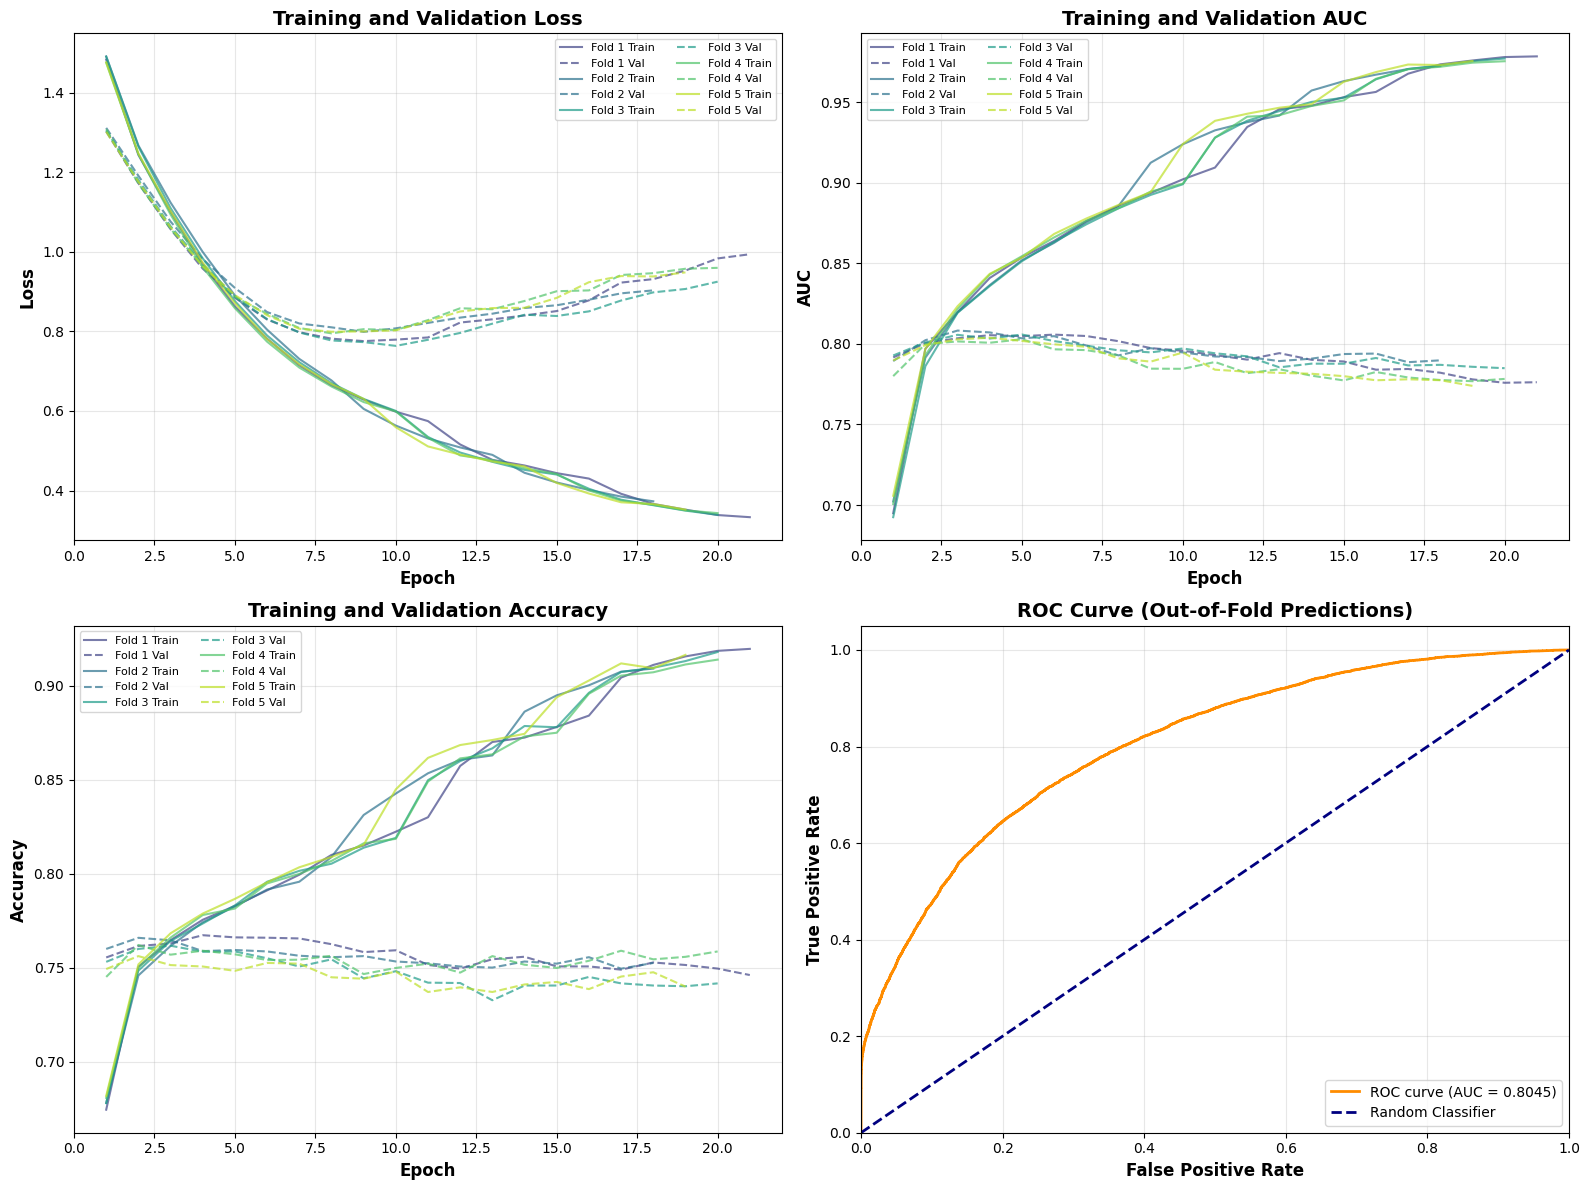


✅ Training history visualized for 5 folds


In [12]:
# Visualize Training History
print("="*70)
print("TRAINING HISTORY VISUALIZATION")
print("="*70)

# Plot training history for all folds
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Fold colors
colors = plt.cm.viridis(np.linspace(0.2, 0.9, N_SPLITS))

# Plot 1: Loss
ax = axes[0, 0]
for fold, (history, color) in enumerate(zip(fold_histories, colors), 1):
    epochs = range(1, len(history.history['loss']) + 1)
    ax.plot(epochs, history.history['loss'], label=f'Fold {fold} Train', color=color, alpha=0.7)
    ax.plot(epochs, history.history['val_loss'], label=f'Fold {fold} Val', color=color, linestyle='--', alpha=0.7)
ax.set_xlabel('Epoch', fontsize=12, fontweight='bold')
ax.set_ylabel('Loss', fontsize=12, fontweight='bold')
ax.set_title('Training and Validation Loss', fontsize=14, fontweight='bold')
ax.legend(fontsize=8, ncol=2)
ax.grid(alpha=0.3)

# Plot 2: AUC
ax = axes[0, 1]
for fold, (history, color) in enumerate(zip(fold_histories, colors), 1):
    epochs = range(1, len(history.history['auc']) + 1)
    ax.plot(epochs, history.history['auc'], label=f'Fold {fold} Train', color=color, alpha=0.7)
    ax.plot(epochs, history.history['val_auc'], label=f'Fold {fold} Val', color=color, linestyle='--', alpha=0.7)
ax.set_xlabel('Epoch', fontsize=12, fontweight='bold')
ax.set_ylabel('AUC', fontsize=12, fontweight='bold')
ax.set_title('Training and Validation AUC', fontsize=14, fontweight='bold')
ax.legend(fontsize=8, ncol=2)
ax.grid(alpha=0.3)

# Plot 3: Accuracy
ax = axes[1, 0]
for fold, (history, color) in enumerate(zip(fold_histories, colors), 1):
    epochs = range(1, len(history.history['accuracy']) + 1)
    ax.plot(epochs, history.history['accuracy'], label=f'Fold {fold} Train', color=color, alpha=0.7)
    ax.plot(epochs, history.history['val_accuracy'], label=f'Fold {fold} Val', color=color, linestyle='--', alpha=0.7)
ax.set_xlabel('Epoch', fontsize=12, fontweight='bold')
ax.set_ylabel('Accuracy', fontsize=12, fontweight='bold')
ax.set_title('Training and Validation Accuracy', fontsize=14, fontweight='bold')
ax.legend(fontsize=8, ncol=2)
ax.grid(alpha=0.3)

# Plot 4: ROC Curve
ax = axes[1, 1]
# Calculate ROC curve for OOF predictions
fpr, tpr, _ = roc_curve(y_train, oof_predictions)
roc_auc = auc(fpr, tpr)
ax.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.4f})')
ax.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Classifier')
ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])
ax.set_xlabel('False Positive Rate', fontsize=12, fontweight='bold')
ax.set_ylabel('True Positive Rate', fontsize=12, fontweight='bold')
ax.set_title('ROC Curve (Out-of-Fold Predictions)', fontsize=14, fontweight='bold')
ax.legend(loc='lower right', fontsize=10)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\n✅ Training history visualized for {N_SPLITS} folds")


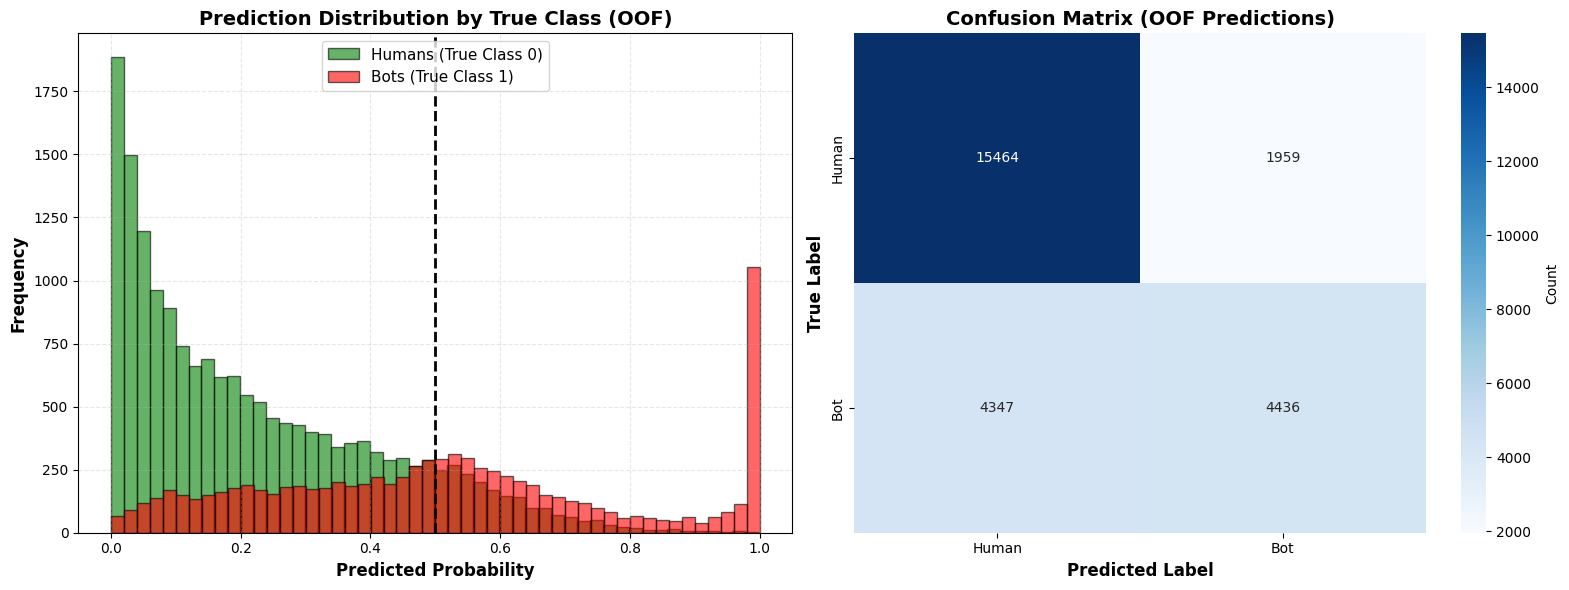


✅ Additional visualizations complete!


In [13]:
# Additional Visualizations
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Prediction distribution comparison
ax = axes[0]
ax.hist(oof_predictions[y_train == 0], bins=50, alpha=0.6, label='Humans (True Class 0)', color='green', edgecolor='black')
ax.hist(oof_predictions[y_train == 1], bins=50, alpha=0.6, label='Bots (True Class 1)', color='red', edgecolor='black')
ax.set_xlabel('Predicted Probability', fontsize=12, fontweight='bold')
ax.set_ylabel('Frequency', fontsize=12, fontweight='bold')
ax.set_title('Prediction Distribution by True Class (OOF)', fontsize=14, fontweight='bold')
ax.legend(loc='upper center', fontsize=11)
ax.grid(alpha=0.3, linestyle='--')
ax.axvline(0.5, color='black', linestyle='--', linewidth=2, label='Decision Threshold')

# Plot 2: Confusion Matrix Heatmap
ax = axes[1]
cm = confusion_matrix(y_train, (oof_predictions > 0.5).astype(int))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, cbar_kws={'label': 'Count'},
            xticklabels=['Human', 'Bot'], yticklabels=['Human', 'Bot'])
ax.set_xlabel('Predicted Label', fontsize=12, fontweight='bold')
ax.set_ylabel('True Label', fontsize=12, fontweight='bold')
ax.set_title('Confusion Matrix (OOF Predictions)', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

print("\n✅ Additional visualizations complete!")


# Summary Report

In [14]:
# Comprehensive Summary Report
print("="*70)
print("MLP NEURAL NETWORK - COMPREHENSIVE SUMMARY REPORT")
print("="*70)

print(f"\n📊 DATASET INFORMATION")
print(f"  Training samples: {len(train):,}")
print(f"  Test samples: {len(test):,}")

print(f"\n🎯 TARGET DISTRIBUTION")
for label, count in y_train.value_counts().sort_index().items():
    emoji = "🤖" if label == 1 else "👤"
    print(f"  {emoji} Class {label}: {count:,} ({count/len(y_train)*100:.1f}%)")

print(f"\n📝 TEXT FEATURES")
print(f"  Text columns processed: {TEXT_COLUMNS}")
print(f"  Word TF-IDF features: 30,000")
print(f"  Char TF-IDF features: 30,000")
print(f"  SVD components: 300")
print(f"  Final feature dimension: {X_text_train_df.shape[1]}")

print(f"\n🏗️ MODEL ARCHITECTURE")
print(f"  Model type: Multi-Layer Perceptron (MLP)")
print(f"  Input features: {X_text_train_df.shape[1]}")
print(f"  Hidden layers: {N_HIDDEN_LAYERS}")
print(f"  Hidden units: {HIDDEN_UNITS}")
print(f"  Total parameters: {model.count_params():,}")
print(f"  Dropout rate: {DROPOUT_RATE}")
print(f"  L2 regularization: {L2_REG}")

print(f"\n⚙️ TRAINING CONFIGURATION")
print(f"  Batch size: {BATCH_SIZE}")
print(f"  Max epochs: {EPOCHS}")
print(f"  Learning rate: {LEARNING_RATE}")
print(f"  Early stopping patience: {EARLY_STOPPING_PATIENCE}")
print(f"  Cross-validation folds: {N_SPLITS}")

print(f"\n📈 MODEL PERFORMANCE")
print(f"  Cross-Validation AUC: {np.mean(cv_scores):.4f} (+/- {np.std(cv_scores):.4f})")
print(f"  Out-of-Fold AUC: {overall_auc:.4f}")
print(f"  Out-of-Fold Accuracy: {overall_acc:.4f}")
print(f"  Precision: {precision:.4f}")
print(f"  Recall: {recall:.4f}")
print(f"  F1-Score: {f1:.4f}")

print(f"\n🎯 INDIVIDUAL FOLD PERFORMANCE")
for i, score in enumerate(cv_scores, 1):
    print(f"  Fold {i}: AUC = {score:.4f}")

print(f"\n💾 SAVED ARTIFACTS")
print(f"  ✓ Submission: {submission_path}")
print(f"  ✓ Text extractor: {text_extractor_path}")
print(f"  ✓ Scaler: {scaler_path}")
print(f"  ✓ OOF predictions: {oof_path}")

print(f"\n📊 TEST PREDICTIONS")
print(f"  Min: {test_predictions.min():.4f}")
print(f"  Max: {test_predictions.max():.4f}")
print(f"  Mean: {test_predictions.mean():.4f}")
print(f"  Std: {test_predictions.std():.4f}")

print(f"\n{'='*70}")
print("NEURAL NETWORK PIPELINE COMPLETE! 🎉")
print(f"{'='*70}")
print(f"\n✅ Ready for Kaggle submission!")
print(f"📈 Expected performance based on CV AUC: {np.mean(cv_scores):.4f}")

print(f"\n💡 KEY INSIGHTS:")
print(f"  • This MLP model processes ONLY textual features from:")
print(f"    - location, description, screen_name")
print(f"  • Text features are extracted using TF-IDF + SVD")
print(f"  • Model uses 3 hidden layers with batch normalization and dropout")
print(f"  • StandardScaler applied to normalize features for neural network")
print(f"  • Can be used as a base model in ensemble with other models")

print(f"\n🔧 NEXT STEPS:")
print(f"  1. Submit to Kaggle and compare with tree-based models")
print(f"  2. Combine with structured features for better performance")
print(f"  3. Use as a base model in meta-ensemble")
print(f"  4. Experiment with different architectures (deeper, wider, etc.)")
print(f"  5. Try different text preprocessing (different n-grams, SVD components)")


MLP NEURAL NETWORK - COMPREHENSIVE SUMMARY REPORT

📊 DATASET INFORMATION
  Training samples: 26,206
  Test samples: 11,232

🎯 TARGET DISTRIBUTION
  👤 Class 0: 17,423 (66.5%)
  🤖 Class 1: 8,783 (33.5%)

📝 TEXT FEATURES
  Text columns processed: ['location', 'description', 'screen_name']
  Word TF-IDF features: 30,000
  Char TF-IDF features: 30,000
  SVD components: 300
  Final feature dimension: 300

🏗️ MODEL ARCHITECTURE
  Model type: Multi-Layer Perceptron (MLP)
  Input features: 300
  Hidden layers: 3
  Hidden units: [512, 256, 128]
  Total parameters: 322,049
  Dropout rate: 0.3
  L2 regularization: 0.001

⚙️ TRAINING CONFIGURATION
  Batch size: 128
  Max epochs: 100
  Learning rate: 0.001
  Early stopping patience: 15
  Cross-validation folds: 5

📈 MODEL PERFORMANCE
  Cross-Validation AUC: 0.8053 (+/- 0.0018)
  Out-of-Fold AUC: 0.8045
  Out-of-Fold Accuracy: 0.7594
  Precision: 0.6937
  Recall: 0.5051
  F1-Score: 0.5845

🎯 INDIVIDUAL FOLD PERFORMANCE
  Fold 1: AUC = 0.8058
  Fold 2

---

## 📝 Notes and Usage Instructions

### About This Notebook

This notebook implements a **Multi-Layer Perceptron (MLP) Neural Network** for Twitter bot detection using **textual features only**:
- **location**: User's location text
- **description**: User's bio/description
- **screen_name**: Username

### Key Features

✅ **Text-Only Model** - Focuses exclusively on textual content  
✅ **TF-IDF Feature Extraction** - Word-level (1-2 grams) + Character-level (3-5 grams)  
✅ **Dimensionality Reduction** - TruncatedSVD to 300 components  
✅ **Deep Neural Network** - 3 hidden layers (512, 256, 128 units)  
✅ **Regularization** - Dropout (0.3) + L2 regularization + Batch normalization  
✅ **5-Fold Cross-Validation** - Robust performance estimation  
✅ **Early Stopping** - Prevents overfitting  

### Architecture Details

**Input Layer:**
- 300 text features (TF-IDF + SVD)

**Hidden Layers:**
1. Dense(512) → BatchNorm → ReLU → Dropout(0.3)
2. Dense(256) → BatchNorm → ReLU → Dropout(0.3)
3. Dense(128) → BatchNorm → ReLU → Dropout(0.3)

**Output Layer:**
- Dense(1) → Sigmoid (binary classification)

### Configuration Options

You can modify these parameters in the configuration cell:

```python
# Architecture
HIDDEN_UNITS = [512, 256, 128]  # Layer sizes
DROPOUT_RATE = 0.3              # Dropout rate
L2_REG = 0.001                  # L2 regularization

# Training
BATCH_SIZE = 128                # Batch size
EPOCHS = 100                    # Max epochs
LEARNING_RATE = 0.001           # Initial learning rate
EARLY_STOPPING_PATIENCE = 15    # Early stopping patience

# Cross-validation
N_SPLITS = 5                    # Number of CV folds
```

### Expected Runtime

- **CPU**: ~15-25 minutes
- **GPU**: ~5-10 minutes

### Performance Tips

1. **Increase model capacity**: Add more layers or units
2. **More text features**: Increase TF-IDF max_features or SVD components
3. **Regularization tuning**: Adjust dropout rate and L2 strength
4. **Learning rate scheduling**: Already using ReduceLROnPlateau
5. **Ensemble**: Combine with tree-based models for better performance

### Comparison with Tree-Based Models

| Aspect | Neural Network (MLP) | Tree-Based (XGBoost/LightGBM) |
|--------|---------------------|-------------------------------|
| **Text Features** | Excellent | Good (with proper encoding) |
| **Feature Scaling** | Required | Not required |
| **Training Time** | Slower | Faster |
| **Interpretability** | Lower | Higher (feature importance) |
| **Regularization** | Dropout, L2 | Tree constraints |
| **Best Use** | Text-heavy data | Structured + text |

### Integration with Ensemble

This model can be used as a base model in the meta-ensemble:

```python
# In meta_ensemble.ipynb
from helpers.nlp import TextFeatureExtractor, combine_text_columns

# Extract text features
train_text = combine_text_columns(train, ['location', 'description', 'screen_name'])
test_text = combine_text_columns(test, ['location', 'description', 'screen_name'])

# Use trained extractor
text_extractor = joblib.load('trained/text_extractor.joblib')
X_text_train = text_extractor.transform(train_text)
X_text_test = text_extractor.transform(test_text)

# Load OOF predictions
oof_mlp = joblib.load('oof_predictions/oof_mlp.pkl')

# Add to meta-features
meta_train['mlp_pred'] = oof_mlp
```

### Troubleshooting

**Problem**: Out of memory error  
**Solution**: Reduce BATCH_SIZE or HIDDEN_UNITS

**Problem**: Overfitting (train AUC >> validation AUC)  
**Solution**: Increase DROPOUT_RATE or L2_REG, reduce model capacity

**Problem**: Underfitting (both train and val AUC low)  
**Solution**: Increase model capacity (more layers/units), train longer

**Problem**: Slow training  
**Solution**: Enable GPU if available, increase BATCH_SIZE

### Next Steps

1. **Submit to Kaggle**: Compare with tree-based models
2. **Combine Features**: Merge text features with structured features
3. **Hyperparameter Tuning**: Use Optuna to optimize architecture
4. **Ensemble**: Use as 4th base model in meta-ensemble
5. **Advanced NLP**: Try transformer-based embeddings (BERT, RoBERTa)

---